 # House Price Prediction Using Machine Learning

 **Dataset:** Seattle Housing Dataset

 **Location:** Seattle, Washington, USA 

 **Task:** House Price Prediction 
 
 **Type:** Supervised Learning-Regression


## Project overview
This project aims to predict house price using machine learning regression models and compare their performance based on MAE (Mean Absolute Error), MSE (Mean Squared Error), and R² (Coefficient of Determination).

## Objective
The main objective of this project is to build an end-to-end machine learning pipeline for house price prediction and compare different regression models.

The following models are evaluated: 

- Linear Regression
- Random Forest Regressor
- XGBoost Regressor

## 1. Import Libraries

In [251]:
import numpy as np 
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 

from sklearn.model_selection import train_test_split 
from sklearn import linear_model 
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

## 2. Load Dataset

In [252]:
df = pd.read_csv("housePrice_USA.csv")

In [253]:
df.head()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


## 3. Data Validation

In [254]:
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

Dataset shape: (4600, 18)

Missing values:
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
street           0
city             0
statezip         0
country          0
dtype: int64

Duplicate rows: 0

Data types:
date              object
price            float64
bedrooms         float64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
street            object
city              object
statezip          object
country           object
dtype: object


## 4. Data Cleaning

In [255]:
print("Number of houses with zero price:", (df['price'] == 0).sum())

Number of houses with zero price: 49


In [256]:
df = df[df['price'] > 0].copy()

In [257]:
print("Dataset shape after removing invalid prices:", df.shape)

Dataset shape after removing invalid prices: (4551, 18)


In [258]:
print("Number of unique values in each column:")
print(df.nunique())

Number of unique values in each column:
date               70
price            1740
bedrooms           10
bathrooms          26
sqft_living       561
sqft_lot         3087
floors              6
waterfront          2
view                5
condition           5
sqft_above        510
sqft_basement     207
yr_built          115
yr_renovated       59
street           4476
city               44
statezip           77
country             1
dtype: int64


In [259]:
df.columns

Index(['date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot',
       'floors', 'waterfront', 'view', 'condition', 'sqft_above',
       'sqft_basement', 'yr_built', 'yr_renovated', 'street', 'city',
       'statezip', 'country'],
      dtype='object')

In [260]:
"country" in df.columns

True

In [261]:
df.shape

(4551, 18)

In [262]:
df = df.drop(columns=['street'])

In [263]:
print(df.shape)

(4551, 17)


In [264]:
df = df.drop(columns=['date'])

In [265]:
print(df.shape)

(4551, 16)


In [266]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4551 entries, 0 to 4599
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   price          4551 non-null   float64
 1   bedrooms       4551 non-null   float64
 2   bathrooms      4551 non-null   float64
 3   sqft_living    4551 non-null   int64  
 4   sqft_lot       4551 non-null   int64  
 5   floors         4551 non-null   float64
 6   waterfront     4551 non-null   int64  
 7   view           4551 non-null   int64  
 8   condition      4551 non-null   int64  
 9   sqft_above     4551 non-null   int64  
 10  sqft_basement  4551 non-null   int64  
 11  yr_built       4551 non-null   int64  
 12  yr_renovated   4551 non-null   int64  
 13  city           4551 non-null   object 
 14  statezip       4551 non-null   object 
 15  country        4551 non-null   object 
dtypes: float64(4), int64(9), object(3)
memory usage: 604.4+ KB


## 5. Exploratory Data Analysis

### Distribution of House Prices
[histogram]

### Price vs Living Area
[scatter plot]

### Correlation Heatmap
[Heatmap]


In [267]:
df.head()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,city,statezip,country
0,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,Shoreline,WA 98133,USA
1,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,Seattle,WA 98119,USA
2,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,Kent,WA 98042,USA
3,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,Bellevue,WA 98008,USA
4,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,Redmond,WA 98052,USA


In [268]:
df.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated
count,4.551000e+03,4551.000000,4551.000000,4551.000000,4.551000e+03,4551.000000,4551.000000,4551.000000,4551.000000,4551.000000,4551.000000,4551.000000,4551.000000
mean,5.579059e+05,3.394639,2.155021,2132.372226,1.483528e+04,1.512195,0.006592,0.234674,3.449352,1822.221710,310.150516,1970.795649,808.564052
std,5.639299e+05,0.904595,0.776351,955.949708,3.596408e+04,0.538531,0.080932,0.765373,0.675160,854.452888,461.987629,29.760073,979.421487
min,7.800000e+03,0.000000,0.000000,370.000000,6.380000e+02,1.000000,0.000000,0.000000,1.000000,370.000000,0.000000,1900.000000,0.000000
25%,3.262643e+05,3.000000,1.750000,1460.000000,5.000000e+03,1.000000,0.000000,0.000000,3.000000,1190.000000,0.000000,1951.000000,0.000000
50%,4.650000e+05,3.000000,2.250000,1970.000000,7.680000e+03,1.500000,0.000000,0.000000,3.000000,1590.000000,0.000000,1976.000000,0.000000
75%,6.575000e+05,4.000000,2.500000,2610.000000,1.097800e+04,2.000000,0.000000,0.000000,4.000000,2300.000000,600.000000,1997.000000,1999.000000
max,2.659000e+07,9.000000,8.000000,13540.000000,1.074218e+06,3.500000,1.000000,4.000000,5.000000,9410.000000,4820.000000,2014.000000,2014.000000


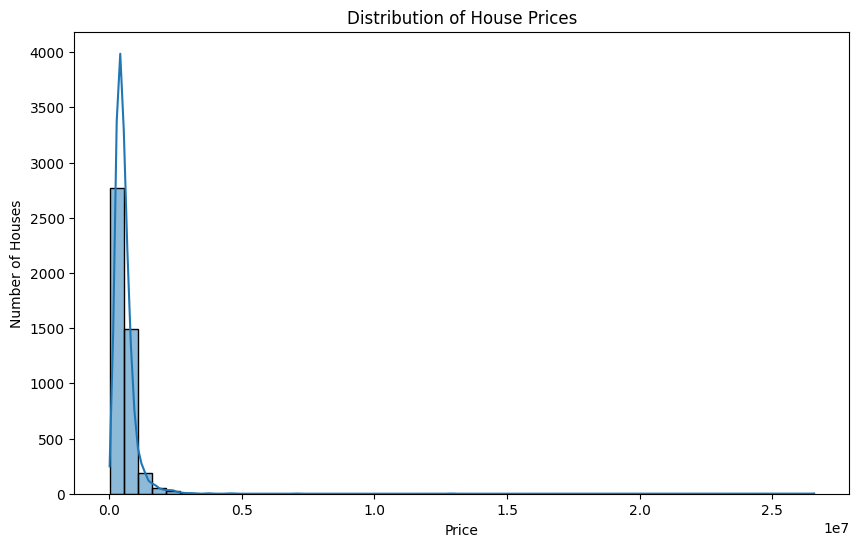

In [269]:
plt.figure(figsize=(10, 6))

sns.histplot(df['price'], bins=50, kde=True)

plt.title('Distribution of House Prices')
plt.xlabel('Price')
plt.ylabel('Number of Houses')

plt.show()

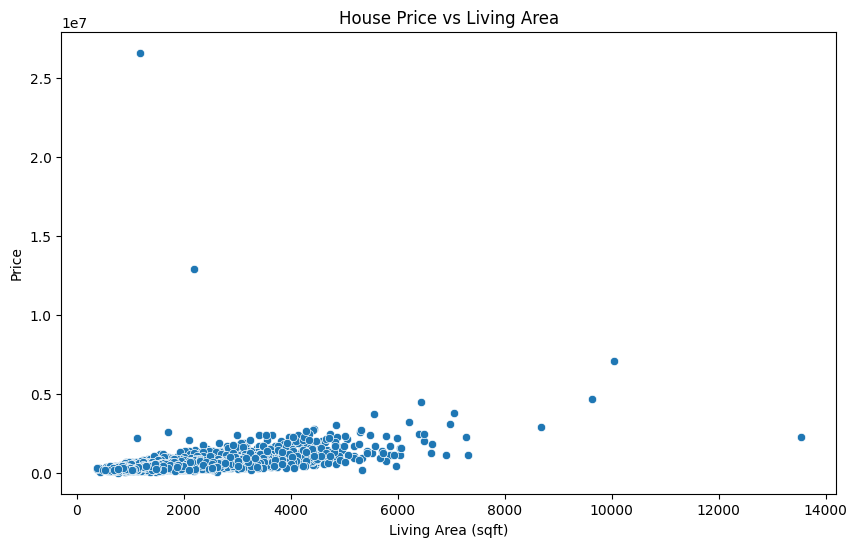

In [285]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='sqft_living',
    y='price'
)

plt.title('House Price vs Living Area')
plt.xlabel('Living Area (sqft)')
plt.ylabel('Price')

plt.show()

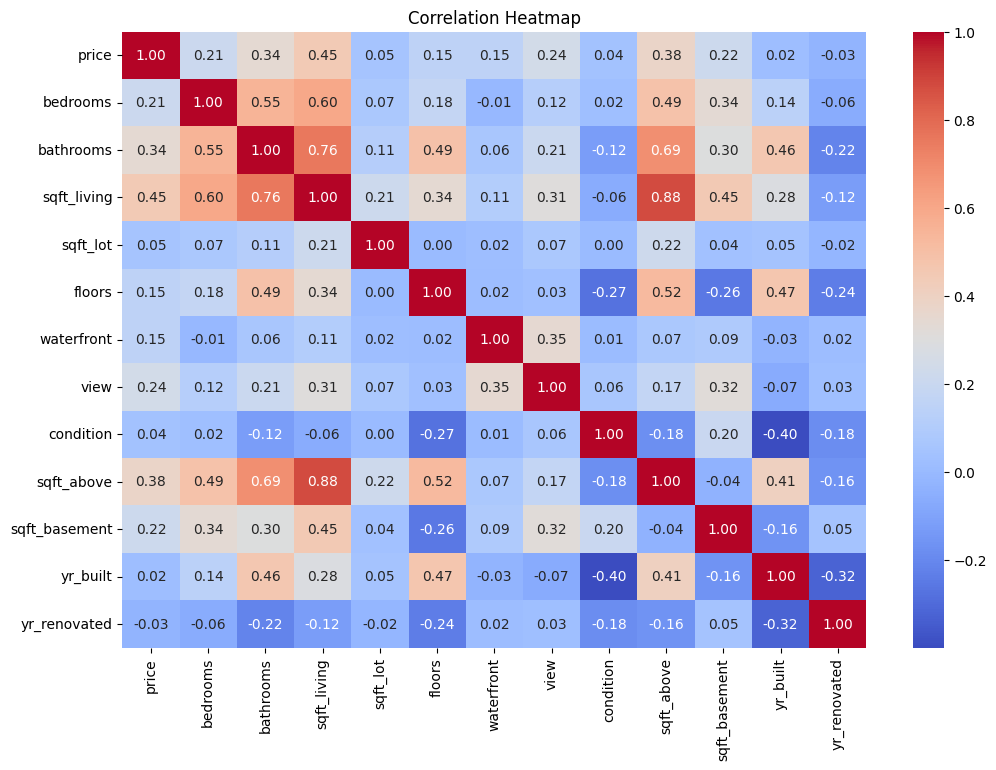

In [270]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

## 6. Data Preprocessing


### Separating Features and Target

In [271]:
y = df['price']

X = df.drop(columns=['price','country'])

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (4551, 14)
y shape: (4551,)


In [272]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (4551, 14)
y shape: (4551,)


In [273]:
print(X.select_dtypes(include='object').columns.tolist())

['city', 'statezip']


### Encoding Categorical Variables

In [274]:
X = pd.get_dummies(
    X,
    columns=['city', 'statezip'],
    drop_first=True
)

In [275]:
print("X shape after encoding:", X.shape)

X shape after encoding: (4551, 131)


### Train/Test Split

In [276]:
X_train, X_test, y_train, y_test = train_test_split(
 X, Y,
    test_size=0.2,
    random_state=42)

In [277]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (3640, 131)
X_test: (911, 131)
y_train: (3640,)
y_test: (911,)


## 7. Model Training

### Linear Regression

In [278]:
model_regression = linear_model.LinearRegression()

model_regression.fit(X_train, y_train)

y_pred_linear = model_regression.predict(X_test)

### Linear Regression Evaluation

In [279]:
mae_linear = mean_absolute_error(y_test, y_pred_linear)
mse_linear = mean_squared_error(y_test, y_pred_linear)
r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression")
print("MAE:", mae_linear)
print("MSE:", mse_linear)
print("R²:", r2_linear)

Linear Regression
MAE: 119164.57451510346
MSE: 45411833071.390594
R²: 0.6947522093535836


### Random Forest Regression

In [280]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

### Random Forest Evaluation

In [281]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest")
print("MAE:", mae_rf)
print("MSE:", mse_rf)
print("R²:", r2_rf)

Random Forest
MAE: 127356.40260896567
MSE: 250209604920.445
R²: -0.6818508290649756


### XGBoost Regression

In [282]:
xgb_model = XGBRegressor(
    n_estimators=100,
    random_state=42
)

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

### XGBoost Evaluation

In [283]:
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
mse_xgb = mean_squared_error(y_test, y_pred_xgb)
r2_xgb = r2_score(y_test, y_pred_xgb)

print("XGBoost")
print("MAE:", mae_xgb)
print("MSE:", mse_xgb)
print("R²:", r2_xgb)

XGBoost
MAE: 110492.03708808232
MSE: 75532043449.58984
R²: 0.49229115350285935


## 8. Model Comparison

In [284]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest', 'XGBoost'],
    'MAE': [mae_linear, mae_rf, mae_xgb],
    'MSE': [mse_linear, mse_rf, mse_xgb],
    'R²': [r2_linear, r2_rf, r2_xgb]
})

results

,Model,MAE,MSE,R²
0,Linear Regression,119164.574515,4.541183e+10,0.694752
1,Random Forest,127356.402609,2.502096e+11,-0.681851
2,XGBoost,110492.037088,7.553204e+10,0.492291


## 9. Conclusion

This project developed an end-to-end machine learning pipeline for house price prediction using a Seattle housing dataset.

Three regression models were trained and evaluated: Linear Regression, Random Forest, and XGBoost.

The results showed that XGBoost achieved the lowest MAE, while Linear Regression achieved the highest R² and the lowest MSE. Random Forest showed poor performance on the test set, with a negative R² score.

Overall, the project demonstrates the complete workflow of data validation, data cleaning, exploratory data analysis, preprocessing, model training, evaluation, and model comparison.
